# 02 · Virtual unwrapping by hand

**Goal.** Take a sheet someone traced through the scroll (a *mesh*) and render it flat ourselves: sample the 3D volume
along the mesh and along its normals. Then check our result against the official **surface volume** the challenge
publishes for the same segment.

**Data.**

| object | what it is | size |
|---|---|---|
| `mesh/*.tifxyz` | three float images `x, y, z`: grid point (i, j) is a 3D position in the scroll (level-0 voxels) | 1.5 MB |
| scroll volume, level 0 | the 9.362 µm scan, streamed as one small crop | ~35 MB here |
| official surface volume | 28 layers × 7,280 × 6,800, the challenge's own rendering of this sheet | we read one tile |

The mesh grid is stored at `scale = 0.05`: one grid step is 20 canvas pixels.

In [ ]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [1]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

In [2]:
x, y, z, meta = vlab.segment_mesh()
print('grid', x.shape, '| scale', meta['scale'], '| valid points', f'{(x > 0).mean():.1%}', '| bbox (x, y, z)', np.round(meta['bbox']).tolist())
print('first valid row of points:'); r = np.argwhere(x > 0)[0]
print(' (x, y, z) =', [round(float(c[r[0], r[1] + k]), 1) for k in range(3) for c in (x, y, z)][:9])

grid (364, 340) | scale [0.05000000074505806, 0.05000000074505806] | valid points 82.6% | bbox (x, y, z) [[1924.0, 2328.0, 1550.0], [4227.0, 4459.0, 8201.0]]
first valid row of points:
 (x, y, z) = [2383.6, 3454.3, 1627.1, 2395.6, 3439.9, 1627.0, 2399.7, 3421.9, 1623.9]


## 1. The sheet in 3D

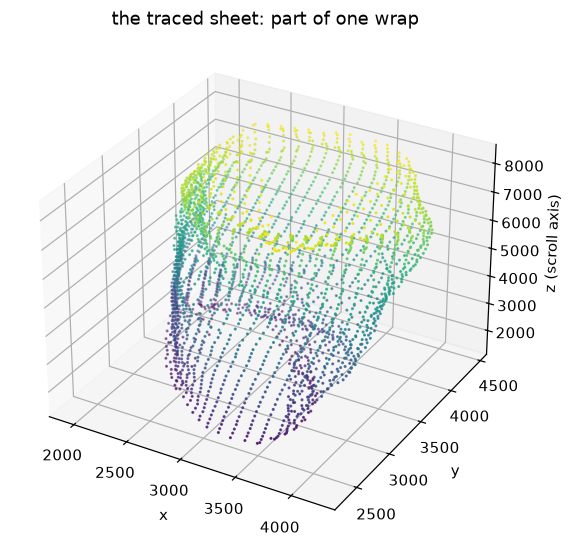

In [3]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
m = x > 0; step = 6
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(projection='3d')
ax.scatter(x[::step, ::step][m[::step, ::step]], y[::step, ::step][m[::step, ::step]], z[::step, ::step][m[::step, ::step]],
           s=1, c=z[::step, ::step][m[::step, ::step]], cmap='viridis')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z (scroll axis)'); ax.set_title('the traced sheet: part of one wrap'); plt.show()

## 2. Render a patch

For a 24 × 24 grid patch (480 × 480 pixels):

1. **Interpolate** the grid to every canvas pixel. Pixel (u, v) sits at grid coordinate (u/20, v/20).
2. **Normals**: the cross product of the two in-plane derivatives.
3. **Sample** the volume at `point + k · normal` for k = −14 … 13 (28 layers), trilinear.

In [4]:
from scipy.ndimage import map_coordinates
i0, j0, g, up = 30, 113, 24, 20
GI, GJ = np.meshgrid(i0 + np.arange(g * up) / up, j0 + np.arange(g * up) / up, indexing='ij')
X, Y, Z = [map_coordinates(c.astype(np.float64), [GI, GJ], order=1) for c in (x, y, z)]
P = np.stack([X, Y, Z], -1)
n = np.cross(np.gradient(P, axis=0), np.gradient(P, axis=1)); n /= np.linalg.norm(n, axis=-1, keepdims=True)
lo = np.floor(np.array([Z.min(), Y.min(), X.min()]) - 20).astype(int); hi = np.ceil(np.array([Z.max(), Y.max(), X.max()]) + 20).astype(int)
t = time.time(); V = vlab.crop(vlab.scroll_volume(0), 'nb02', *[slice(a, b) for a, b in zip(lo, hi)])
print(f'volume crop {V.shape} ({V.nbytes / 1e6:.0f} MB) in {time.time() - t:.1f}s')
Pz = np.stack([Z, Y, X], -1) - lo; N = n[..., [2, 1, 0]]
mine = np.stack([map_coordinates(V, (Pz + k * N).reshape(-1, 3).T, order=1).reshape(X.shape) for k in np.arange(28) - 14])
print('our surface volume', mine.shape)

volume crop (541, 137, 539) (40 MB) in 1.8s


our surface volume (28, 480, 480)


## 3. Check it against the official rendering

correlation per layer: mean 0.932, min 0.899, max 0.943


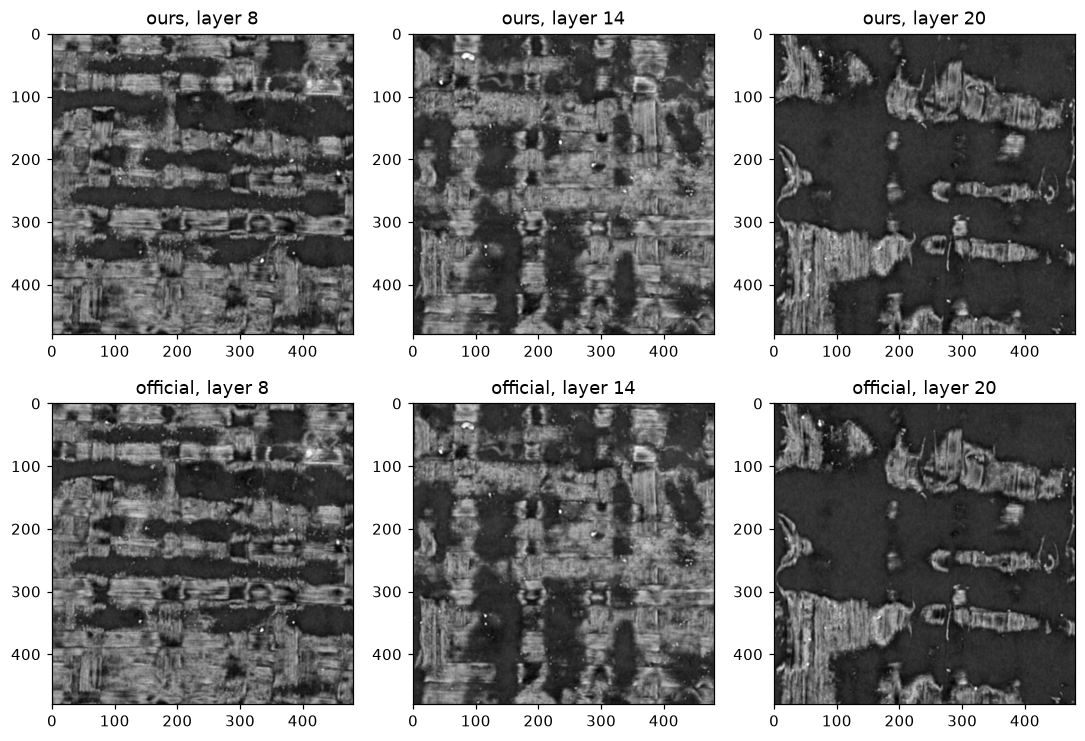

In [5]:
S = vlab.segment_surface(0)
ref = vlab.crop(S, 'nb02ref', slice(None), slice(i0 * up, (i0 + g) * up), slice(j0 * up, (j0 + g) * up)).astype(float)
c = [np.corrcoef(mine[k][40:-40, 40:-40].ravel(), ref[k][40:-40, 40:-40].ravel())[0, 1] for k in range(28)]
print(f'correlation per layer: mean {np.mean(c):.3f}, min {min(c):.3f}, max {max(c):.3f}')
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for col, k in enumerate((8, 14, 20)):
    ax[0, col].imshow(mine[k]); ax[0, col].set_title(f'ours, layer {k}')
    ax[1, col].imshow(ref[k]); ax[1, col].set_title(f'official, layer {k}')
plt.show()

A correlation around 0.93 means we reproduced the challenge's renderer from its mesh and the raw scan.
The rest is interpolation detail (their resampling and normal smoothing differ slightly from ours).

**A trap we hit building this.** Upsampling the grid with `scipy.ndimage.zoom` instead of interpolating at
`pixel / 20` gives correlation **0.37**: `zoom` stretches the grid so its corners align, which shifts every interior
point by up to half a cell. The geometry must be resampled at exactly the pixel positions the format defines.

## 4. Why 28 layers?

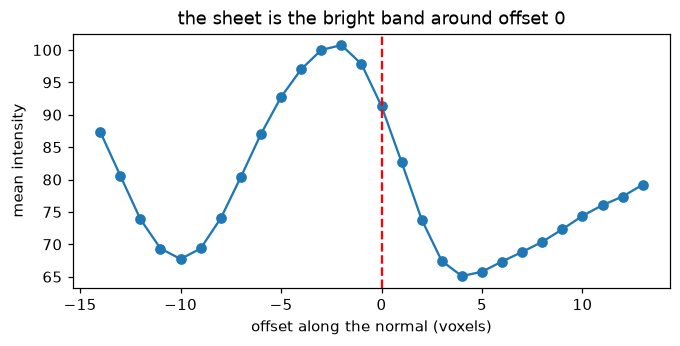

In [6]:
prof = mine.reshape(28, -1).mean(1)
plt.figure(figsize=(7, 3)); plt.plot(np.arange(28) - 14, prof, 'o-'); plt.axvline(0, c='r', ls='--')
plt.xlabel('offset along the normal (voxels)'); plt.ylabel('mean intensity'); plt.title('the sheet is the bright band around offset 0'); plt.show()

The papyrus is a few voxels thick and the mesh is not exactly on it. Rendering a slab of layers lets the ink model
look *into* the sheet and forgive a mesh that is off by a few voxels.

## Check yourself

1. What happens to the rendering if a normal flips sign halfway across the patch?
2. Why does the slab have to be wider when the mesh was traced at a coarser resolution?
3. How would a sheet switch (the mesh jumping to the neighbouring wrap) look in the rendered layers?